# Notebook 02: Highway Traffic & Corridor Demand

## What is this notebook about?
In Notebook 01, we found out which NJ counties have the most electric vehicles (EVs). 

Now, we want to look at major highways like the **NJ Turnpike** and **Garden State Parkway**. By combining highway traffic numbers with our county EV data, we can figure out which highway stretches have the highest need for EV charging stations.

## What we will do:
1. **Load County Data:** Bring in the cleaned county EV numbers we saved in Notebook 01.
2. **Load Highway Traffic Data:** Import daily traffic counts for major NJ highways.
3. **Find High-Demand Corridors:** See where heavy highway traffic cuts through high-EV counties.
4. **Save the Output:** Export a clean dataset to use for modeling charging stations in Notebook 03.

## Step 1: Load the Files

### What we are doing:
We are loading two datasets into our notebook:
1. `county_ev_growth_2019_2025.csv` (the cleaned EV count file we saved in Notebook 01).
2. `TrafficCount2025DataSetwithAADTs.csv` (the state highway traffic counts for 2025).

### Why:
We need both files in Python so we can combine EV numbers with traffic counts.

In [2]:
import pandas as pd

# 1. Load processed county EV data from Notebook 01
df_county_ev = pd.read_csv("../data/processed/county_ev_growth_2019_2025.csv")

# 2. Load highway traffic (AADT) dataset
# Note: Update the filename below if your traffic dataset is named differently in ../data/raw/
df_traffic = pd.read_csv("../data/raw/TrafficCount2025DataSetwithAADTs.csv")

# Display the first few rows of both datasets
print("Processed County EV Data:")
display(df_county_ev.head())

print("\nHighway Traffic (AADT) Data:")
display(df_traffic.head())

Processed County EV Data:


,County,ev_count_2019,ev_count_2022,ev_count_2025,absolute_growth,pct_growth
0,Bergen,4732,13190,40397,35665,753.698225
1,Middlesex,3349,10034,32347,28998,865.870409
2,Monmouth,2497,7980,23271,20774,831.958350
3,Essex,2514,8354,20882,18368,730.628481
4,Morris,2364,6792,19166,16802,710.744501



Highway Traffic (AADT) Data:


,Location ID,LRS Id,LRS Location Point,Latitude,Longitude,Functional Class,Functional Class Text,Rural/Urban,County,Community,AADT,AADT Year,Perm Station,Direction
0,000015,00000015__,7.1,40.97611,-74.60226,2,Freeway & Expressway,U,Morris,Jefferson Twp,39475.0,2025.0,True,2-WAY
1,000015_NB,00000015__,7.1,40.97611,-74.60226,2,Freeway & Expressway,U,Morris,Jefferson Twp,18705.0,2025.0,True,NB
2,000015_SB,00000015__,7.1,40.97611,-74.60226,2,Freeway & Expressway,U,Morris,Jefferson Twp,20769.0,2025.0,True,SB
3,000017,00000017__,25.0,41.09331,-74.15561,2,Freeway & Expressway,U,Bergen,Mahwah Twp,39421.0,2025.0,True,1-WAY
4,000017_SB,00000017__,25.0,41.09331,-74.15561,2,Freeway & Expressway,U,Bergen,Mahwah Twp,39421.0,2025.0,True,SB


## Step 2: Clean Up Traffic Numbers and Merge

### What we are doing:
1. Filter the traffic data to keep only standard 2-way/1-way traffic rows so we don't double-count vehicles.
2. Calculate two simple traffic numbers for each county:
   * **Average Traffic (`avg_aadt`):** The average daily cars on highways in that county.
   * **Peak Traffic (`max_aadt`):** The busiest single highway spot in that county.
3. Merge the traffic summary with our county EV numbers using `County` as the link.

### Why:
Traffic sensors record data at hundreds of different spots. Grouping by county lets us match total highway traffic directly to total county EVs.

In [3]:
# 1. Filter for 2-WAY or total directional traffic to avoid double counting
df_traffic_clean = df_traffic[df_traffic['Direction'].isin(['2-WAY', '1-WAY'])].copy()

# 2. Calculate average and total AADT per County
traffic_by_county = df_traffic_clean.groupby('County').agg(
    avg_aadt=('AADT', 'mean'),
    max_aadt=('AADT', 'max'),
    total_traffic_points=('AADT', 'count')
).reset_index()

# 3. Merge traffic summary with county EV growth data
df_merged = pd.merge(df_county_ev, traffic_by_county, on='County', how='inner')

# Round averages for display
df_merged['avg_aadt'] = df_merged['avg_aadt'].round(0).astype(int)
df_merged['max_aadt'] = df_merged['max_aadt'].astype(int)

# Display top counties with EV counts and traffic
display(df_merged.head(10))

,County,ev_count_2019,ev_count_2022,ev_count_2025,absolute_growth,pct_growth,avg_aadt,max_aadt,total_traffic_points
0,Bergen,4732,13190,40397,35665,753.698225,19268,163264,95
1,Middlesex,3349,10034,32347,28998,865.870409,15202,126941,171
2,Monmouth,2497,7980,23271,20774,831.958350,13928,54657,119
3,Essex,2514,8354,20882,18368,730.628481,15810,117939,42
4,Morris,2364,6792,19166,16802,710.744501,24471,159325,66
5,Somerset,2172,5635,15761,13589,625.644567,18884,97159,49
6,Mercer,1985,5322,14039,12054,607.254408,11635,93943,203
7,Ocean,1012,4576,14038,13026,1287.154150,15123,55380,113
8,Union,1476,4512,13683,12207,827.032520,11986,100424,61
9,Hudson,1165,4581,12824,11659,1000.772532,12269,76944,32


## Step 3: Calculate the Corridor Demand Index (CDI)

### What we are doing:
We multiply local EV counts by peak highway traffic, then divide by 1,000,000 to keep the numbers manageable:

$$\text{CDI} = \frac{\text{ev\_count\_2025} \times \text{max\_aadt}}{1,000,000}$$

Finally, we save the results to `corridor_demand_overlay.csv`.

### Why:
A county with lots of EVs *and* heavy highway traffic needs chargers much more than a quiet rural county. This score gives us a single ranking number to easily spot top priorities.

In [4]:
# 1. Compute Corridor Demand Index (CDI)
df_merged['corridor_demand_index'] = (df_merged['ev_count_2025'] * df_merged['max_aadt']) / 1_000_000

# 2. Sort by highest demand score
df_corridor_ranked = df_merged.sort_values(by='corridor_demand_index', ascending=False).reset_index(drop=True)

# 3. Round CDI score for clean display
df_corridor_ranked['corridor_demand_index'] = df_corridor_ranked['corridor_demand_index'].round(2)

# 4. Save processed corridor demand metrics
df_corridor_ranked.to_csv("../data/processed/corridor_demand_overlay.csv", index=False)

# Display Top 10 High-Demand Corridors
print("Top 10 NJ County Highway Corridors by Charging Demand Index:")
display(df_corridor_ranked[['County', 'ev_count_2025', 'max_aadt', 'avg_aadt', 'corridor_demand_index']].head(10))

Top 10 NJ County Highway Corridors by Charging Demand Index:


,County,ev_count_2025,max_aadt,avg_aadt,corridor_demand_index
0,Bergen,40397,163264,19268,6595.38
1,Middlesex,32347,126941,15202,4106.16
2,Morris,19166,159325,24471,3053.62
3,Essex,20882,117939,15810,2462.80
4,Somerset,15761,97159,18884,1531.32
5,Camden,10844,140749,11899,1526.28
6,Passaic,9319,149586,15115,1393.99
7,Union,13683,100424,11986,1374.10
8,Burlington,11078,123708,14004,1370.44
9,Mercer,14039,93943,11635,1318.87


## Step 4: Chart the Top Corridors

### What we are doing:
We make a bar chart showing the top 10 counties based on their CDI demand score.

### Why:
Visualizing the results makes it clear at a glance which highway corridors (like Bergen and Middlesex) need new charging stations first.

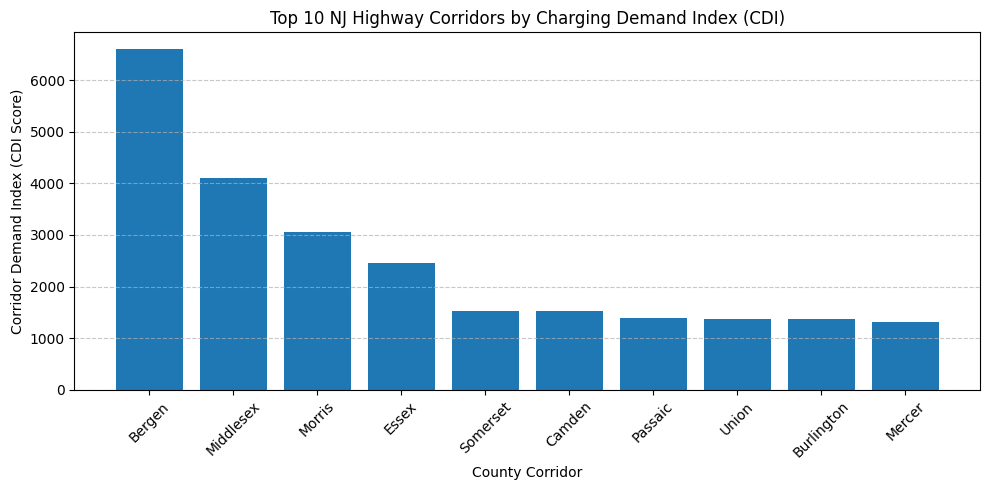

In [5]:
import matplotlib.pyplot as plt

# Get Top 10 Corridors
top_10_corridors = df_corridor_ranked.head(10)

# Create Bar Chart
plt.figure(figsize=(10, 5))
plt.bar(top_10_corridors['County'], top_10_corridors['corridor_demand_index'], color='#1f77b4')

plt.title('Top 10 NJ Highway Corridors by Charging Demand Index (CDI)')
plt.xlabel('County Corridor')
plt.ylabel('Corridor Demand Index (CDI Score)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Key Findings & Summary
* **Top Infrastructure Priority Corridors:** Bergen, Middlesex, and Morris represent the highest-priority highway corridors in New Jersey for large-scale EV charging deployment.
* **Traffic & Density Convergence:** Counties like Morris and Camden rank higher in highway demand than local registrations alone suggest, driven by heavy commuter traffic flows (AADT > 140k-159k).
* **Exported Dataset:** Processed corridor demand metrics have been saved to `data/processed/corridor_demand_overlay.csv` for service area allocation in **Notebook 03**.